# Clasificación de tonos del mandarín con Tone Perfect: pasos y decisiones

Este notebook recorre el pipeline de monosílabos de principio a fin: datos, extracción de F0, corrección de errores de octava, baseline con features, calibración, CNN sobre el contorno, embeddings congelados de HuBERT y el backend del MVP. En cada paso se explica qué se hizo, por qué, qué alternativas se descartaron y qué limitaciones quedan.

El notebook **no vuelve a ejecutar los pasos pesados** (F0 de 9.839 ficheros, embeddings, entrenamientos). Lee lo que dejan los scripts en `data/` y `outputs/`, y solo calcula en vivo lo que es ligero y ayuda a entender una decisión. Para regenerarlo todo desde el audio:

```powershell
uv sync
uv run python scripts/01_explorar_toneperfect.py
uv run python scripts/02_contornos_f0.py --method pyin --n-per-cell 40
uv run python scripts/02_contornos_f0.py --method praat --n-per-cell 0
uv run python scripts/03_features_toneperfect.py --method praat
uv run python scripts/21_baseline_toneperfect.py --method praat
uv run python scripts/22_calibrar_toneperfect.py --method praat --set base
uv run python scripts/22_calibrar_toneperfect.py --method praat --set con_duracion
uv run python scripts/23_cnn_toneperfect.py --method praat
uv run python scripts/22_calibrar_toneperfect.py --baseline-dir outputs/cnn_toneperfect --set cnn
uv run python scripts/04_embeddings_toneperfect.py
uv run python scripts/24_lineal_embeddings_toneperfect.py
uv run python scripts/22_calibrar_toneperfect.py --baseline-dir outputs/lineal_toneperfect --method chinese-hubert-base --set lineal
uv run python scripts/25_entrenar_cnn_final.py --method praat
uv run python scripts/05_exportar_silabas_toneperfect.py
uv run python scripts/26_evaluar_voz_corregida.py --per-cell 25
uv run python scripts/27_contorno_objetivo_personalizado.py
uv run python scripts/28_evaluar_calibracion.py
```

El pipeline de bisílabos con AISHELL-3 queda fuera de este notebook; sus decisiones están en `docs/corpus-bisilabos.md`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from joblib import Parallel, delayed

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT, DATA = ROOT / "outputs", ROOT / "data"
AUDIO = DATA / "raw" / "toneperfect" / "tone_perfect"
TONES = [1, 2, 3, 4]
pd.set_option("display.precision", 3)


def show(path, width=950):
    display(Image(filename=str(path), width=width))


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def audio_path(name):
    return str(AUDIO / f"{name}_MP3.mp3")


def predictions(oof_path):
    oof = pd.read_parquet(oof_path)
    oof["pred"] = np.array(TONES)[oof[[f"p{t}" for t in TONES]].to_numpy().argmax(1)]
    return oof

## 1. Datos: Tone Perfect

Tone Perfect (Michigan State University) son grabaciones de sílabas aisladas del mandarín: 410 sílabas en los 4 tonos leídas por 6 hablantes nativos, 3 mujeres (FV1–FV3) y 3 hombres (MV1–MV3). El nombre de cada fichero codifica la sílaba, el tono y el hablante (`ma3_FV1_MP3.mp3`), y `src/tonos/data.py` lo interpreta; los XML de metadatos que acompañan al audio no hacen falta para la clasificación.

Se eligió porque el pilar 1 del TFM es clasificar el tono de una sílaba aislada, que es justo lo que contiene. El plan B (recortar monosílabos de AISHELL-3) ya no hizo falta al llegar el acceso el 17 de noviembre.

In [2]:
index = pd.read_csv(OUT / "exploracion" / "indice_toneperfect.csv")
pd.crosstab(index.speaker, index.tone, margins=True)

tone,1,2,3,4,All
speaker,,,,,
FV1,410,410,410,410,1640
FV2,410,410,410,410,1640
FV3,409,410,410,410,1639
MV1,410,410,410,410,1640
MV2,410,410,410,410,1640
MV3,410,410,410,410,1640
All,2459,2460,2460,2460,9839


In [3]:
speakers_per_item = index.groupby(["syllable", "tone"]).speaker.apply(set)
incomplete = speakers_per_item[speakers_per_item.apply(len) < 6]
print("Pares sílaba-tono incompletos:", {k: sorted({"FV1", "FV2", "FV3", "MV1", "MV2", "MV3"} - v) for k, v in incomplete.items()})

Pares sílaba-tono incompletos: {('jiao', 1): ['FV3']}


El corpus está perfectamente equilibrado (25 % por tono) y solo falta una grabación, `jiao1_FV3`. Dos rasgos condicionan todo lo que sigue:

**Solo hay 6 hablantes.** Toda la evaluación se hace dejando fuera un hablante por fold (6 folds), porque lo que interesa es cómo funciona con una voz que el modelo no ha oído. Con 6 hablantes cada fold es una sexta parte del corpus y la dispersión entre hablantes es tan informativa como la media.

**La duración depende del tono, y también del hablante.** La tabla de abajo es la duración de la sílaba tras recortar silencios (la misma que usa el baseline). T3 es el más largo y T4 el más corto en todos los hablantes, pero MV1 y MV3 hablan mucho más rápido que el resto: el T3 de MV1 dura menos que el T1 de FV1. Esto anticipa el problema de la sección 4.

In [4]:
features = pd.read_parquet(DATA / "processed" / "feats_toneperfect_praat.parquet")
features.pivot_table(index="speaker", columns="tone", values="dur", aggfunc="mean").round(2)

tone,1,2,3,4
speaker,,,,
FV1,0.82,0.84,0.87,0.65
FV2,0.61,0.70,0.86,0.55
FV3,0.78,0.85,1.01,0.56
MV1,0.53,0.56,0.60,0.41
MV2,0.67,0.74,0.92,0.52
MV3,0.49,0.54,0.67,0.39


## 2. Extracción de F0: pYIN frente a Praat

El tono es un patrón de altura (F0) en el tiempo, así que el primer paso es estimar el F0. El pipeline común (`src/tonos/f0.py`) carga a 16 kHz, recorta silencios (`top_db=30`), estima el F0 cada 10 ms y lo pasa a semitonos respecto a la media geométrica del F0 de cada hablante. Esa normalización elimina la diferencia de registro entre voces (un hombre y una mujer dicen el mismo T1 a alturas muy distintas) y conserva la forma y el nivel relativo del tono.

Se compararon dos estimadores sobre la misma muestra (40 grabaciones por hablante y tono, 960 en total), ambos con el rango genérico de 60–500 Hz y sin ninguna corrección. pYIN se lee de la salida de `02_contornos_f0.py`; Praat se recalcula aquí sobre las mismas grabaciones porque su salida guardada ya es la corregida.

In [5]:
from tonos.f0 import extract_f0, fixed_length_contour, hz_to_st, speaker_reference_hz

sample = pd.read_csv(OUT / "contornos" / "meta_pyin.csv")
sample_paths = [str(ROOT / Path(p.replace("\\", "/"))) for p in sample.path]
praat_raw = Parallel(n_jobs=-1)(delayed(extract_f0)(p, "praat") for p in sample_paths)
sample["praat_failed"] = [np.isnan(fixed_length_contour(f)).all() for f in praat_raw]
sample["praat_voiced_ratio"] = [np.isfinite(f).mean() for f in praat_raw]

comparison = pd.DataFrame({
    "pYIN: sin contorno (%)": sample.groupby("tone").failed.mean() * 100,
    "Praat: sin contorno (%)": sample.groupby("tone").praat_failed.mean() * 100,
    "pYIN: frames sonoros (mediana)": sample.groupby("tone").voiced_ratio.median(),
    "Praat: frames sonoros (mediana)": sample.groupby("tone").praat_voiced_ratio.median(),
})
comparison.round(2)

,pYIN: sin contorno (%),Praat: sin contorno (%),pYIN: frames sonoros (mediana),Praat: frames sonoros (mediana)
tone,,,,
1,0.00,0.0,0.91,0.92
2,0.00,0.0,0.92,0.93
3,0.42,0.0,0.77,0.81
4,10.00,0.0,0.56,0.67


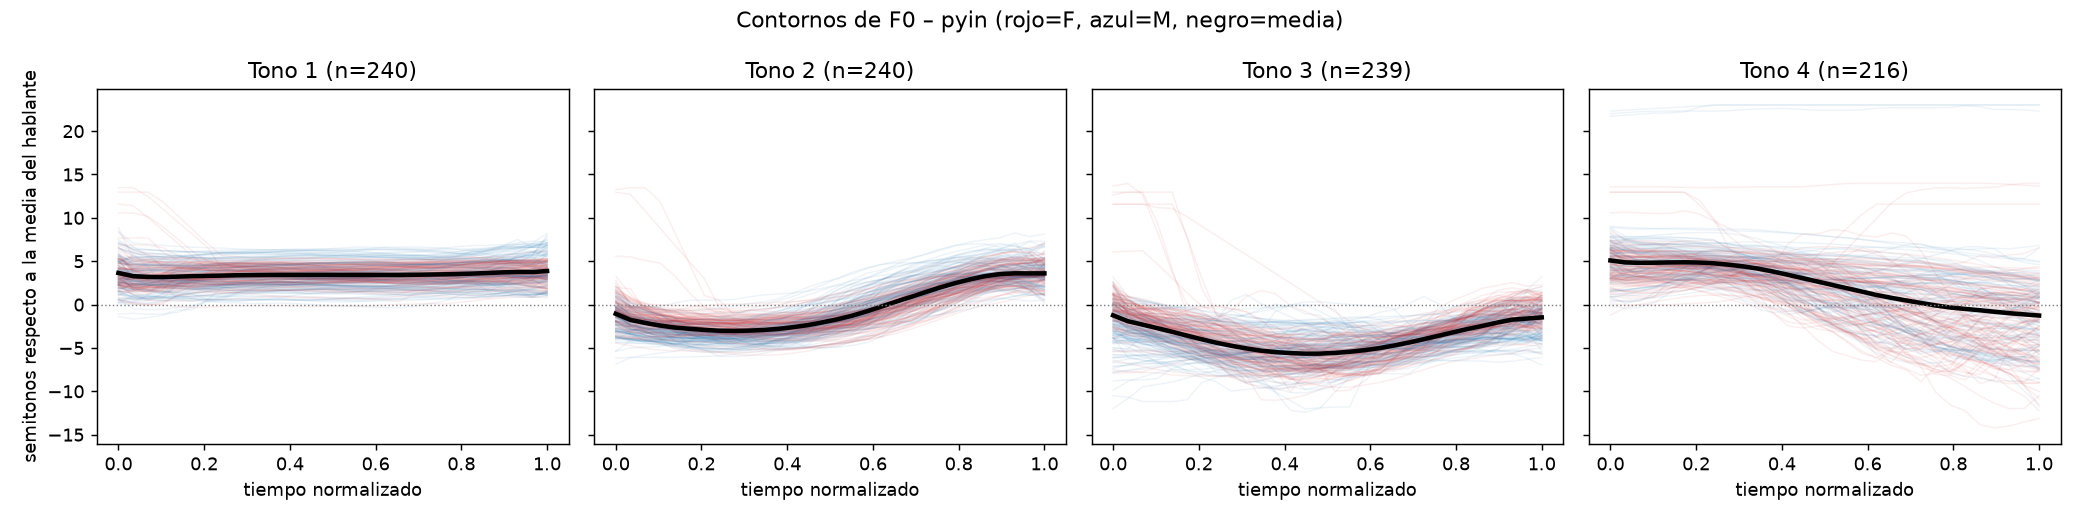

In [6]:
show(OUT / "contornos" / "contornos_por_tono_pyin.png")

pYIN pierde el 10 % de los T4 y, en los que no pierde, deja de detectar voz antes del final, de modo que la caída media del T4 sale de unos 6 st, frente a unos 11 con Praat corregido. Además tiene errores de octava enteros (las líneas planas a +12 y +22 st de la figura). Es un problema serio porque T4 frente a T3 es justo la distinción difícil.

Praat no pierde ninguna grabación y conserva más frames sonoros en T3 y T4. Su defecto, visible en la sección siguiente, son los saltos de octava. **Decisión: Praat como estimador de F0, añadiendo una corrección de octava.** CREPE queda implementado en `f0.py` para AISHELL-3, pero no se comparó en Tone Perfect.

## 3. Corrección de errores de octava

Un error de octava es que el estimador elige un candidato al doble o a la mitad del F0 real: el contorno salta ±12 st de un frame al siguiente. En Praat aparecían sobre todo en T3 de hombres (saltos hacia arriba, en la zona grave y con voz *creaky*) y al final de T4 de mujeres (saltos hacia abajo).

Para esta sección se calcula aquí el F0 corregido de todo el corpus con la misma función que usan los scripts (`extract_corpus_f0`, unos 20 segundos), y además el F0 sin corregir de los ejemplos.

In [7]:
from tonos.f0 import clean_f0, extract_corpus_f0

corpus_paths = [str(ROOT / Path(p.replace("\\", "/"))) for p in index.path]
corrected_f0 = extract_corpus_f0(corpus_paths, index.speaker.tolist(), "praat")
speaker_refs = {s: speaker_reference_hz([corrected_f0[i] for i in g.index]) for s, g in index.groupby("speaker")}


def row_of(name):
    return index.index[index.path.str.contains(f"{name}_MP3", regex=False)][0]

C:\Users\pc\Desktop\PROYECTOS\TFM - EVOLVE\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 3.1 Por qué no se reutilizó `clean_f0`

El proyecto ya tenía `clean_f0` (usado con AISHELL-3), que mueve una octava los frames a más de 9 st de la mediana *de la propia frase*. Con frases largas funciona, pero con una sílaba aislada la mediana es la de esa sílaba. Un T4 real no cae en línea recta: mantiene la altura y luego cae, así que su mediana queda arriba y el final de la caída se aleja más de 9 st de ella. Aplicado sobre los T4 ya corregidos, `clean_f0` movería o borraría algún frame en más de 6 st en la mitad de ellos:

T4 que clean_f0 altera en más de 6 st: 50.7 %


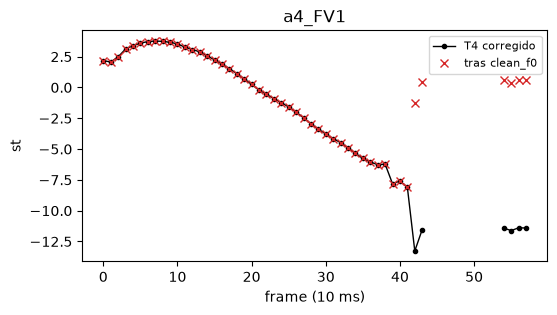

In [8]:
def max_change_st(before, after):
    voiced = np.isfinite(before)
    change = np.abs(hz_to_st(after[voiced], 1.0) - hz_to_st(before[voiced], 1.0))
    return np.where(np.isfinite(change), change, np.inf).max() if voiced.any() else 0.0


t4_rows = index.index[index.tone == 4]
changes = pd.Series([max_change_st(corrected_f0[i], clean_f0(corrected_f0[i], medfilt=1)) for i in t4_rows], index=t4_rows)
print(f"T4 que clean_f0 altera en más de 6 st: {(changes > 6).mean() * 100:.1f} %")

example = changes[changes > 6].index[0]
name = Path(index.path[example]).stem.replace("_MP3", "")
reference = speaker_refs[index.speaker[example]]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(hz_to_st(corrected_f0[example], reference), "k.-", lw=1, label="T4 corregido")
ax.plot(hz_to_st(clean_f0(corrected_f0[example], medfilt=1), reference), "x", color="tab:red", label="tras clean_f0")
ax.set_title(name); ax.set_xlabel("frame (10 ms)"); ax.set_ylabel("st"); ax.legend(fontsize=8); plt.show()

### 3.2 La corrección adoptada, en dos pasos

**Paso 1: rango de búsqueda adaptado a cada hablante** (`speaker_pitch_range`, método de dos pasadas de De Looze y Hirst). Una primera pasada con 60–500 Hz da la distribución de F0 de cada hablante; la segunda se limita a [0,5·Q1, 1,5·Q3]. Así el estimador no puede elegir candidatos absurdamente lejos del registro de esa voz. El suelo habitual es 0,75·Q1, pero aquí se bajó a 0,5·Q1 porque T3 y T4 bajan de forma legítima hasta unos 12 st por debajo de la media.

Este paso eliminó los picos de ±20 st, pero no los saltos de octava que caen *dentro* del rango (por ejemplo, un T3 masculino a 90 Hz duplicado a 180 Hz sigue siendo un valor plausible para ese hombre).

**Paso 2: corrección por continuidad** (`fix_octave_jumps`). La voz no cambia más de unos pocos semitonos en 10 ms, así que un salto de más de 6 st entre frames sonoros consecutivos parte el contorno en tramos. Se toma un tramo como correcto y, hacia cada lado, cada tramo vecino se desplaza un múltiplo de 12 st para unirlo con él. Al final se descartan los frames fuera del rango del hablante.

Esta corrección necesitó tres iteraciones, y cada una corrigió un error visible de la anterior:

1. La primera tomaba como referencia el tramo más largo. En los T3 con voz *creaky* el tramo erróneo ocupa casi toda la sílaba, y la corrección movía de octava contornos enteros (aparecieron bandas paralelas a +10 y −13 st). Se pasó a tomar el tramo más largo **cuya mediana está a menos de 9 st de la referencia del hablante**. Una rama de respaldo para sílabas sin ningún tramo en registro no se activaba en ningún contorno y se eliminó.
2. La segunda comparaba un solo frame a cada lado del corte y desplazaba cualquier hueco de más de 6 st. Al preparar este notebook se vio que estropeaba contornos reales: un único frame anómalo al final de un tramo arrastraba una octava hacia abajo a todo el tramo siguiente, y un salto real de 7 st a través de un hueco sordo se redondeaba a una octava.
3. La versión final mide el hueco con la **mediana de 3 frames a cada lado** y solo desplaza si el hueco es **de 9 st o más**, es decir, más cerca de una octava que de un cambio real. Con ella los T3 fuera de registro bajan del 3,3 % al 1,6 %. El coste: la CNN pasó de 0,989–0,990 a 0,987–0,988 de accuracy (3 semillas). Se aceptó porque el contorno no es solo una entrada del modelo: es lo que ve el usuario en la app y lo que usará la resíntesis con WORLD, y ahí un contorno desplazado una octava es un error visible.

Abajo, dos sílabas reales sin corregir y corregidas con la versión final:

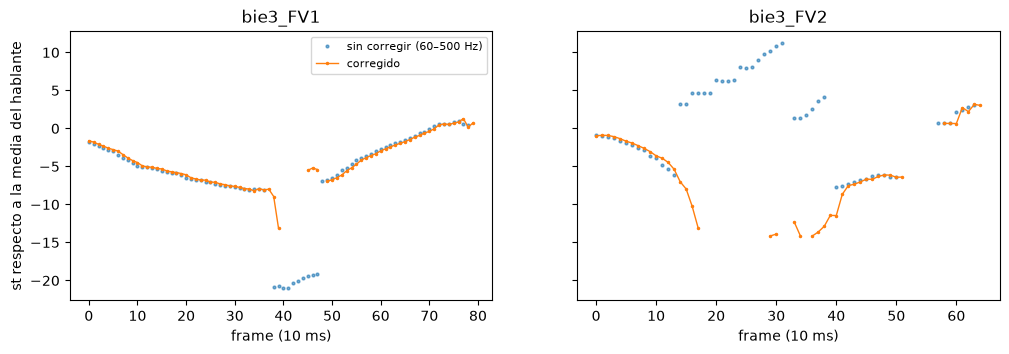

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, name in zip(axes, ["bie3_FV1", "bie3_FV2"]):
    row = row_of(name)
    reference = speaker_refs[index.speaker[row]]
    ax.plot(hz_to_st(extract_f0(audio_path(name), "praat"), reference), ".", ms=4, alpha=0.6, label="sin corregir (60–500 Hz)")
    ax.plot(hz_to_st(corrected_f0[row], reference), ".-", ms=3, lw=1, label="corregido")
    ax.set_title(name)
    ax.set_xlabel("frame (10 ms)")
axes[0].set_ylabel("st respecto a la media del hablante")
axes[0].legend(fontsize=8)
plt.show()

En `bie3_FV1`, Praat sin corregir estima un tramo una octava por debajo (en torno a −20 st); la versión final lo recoloca y la subida final del T3 queda intacta, de −7 a +1 st. El frame aislado a −13 st al final del primer tramo sigue ahí, pero ya no arrastra al tramo siguiente, que era el fallo de la segunda iteración. En `bie3_FV2` el F0 sin corregir salta entre varios niveles; la versión final conserva la subida final (+1 a +3 st), porque el salto de unos 7 st que la precede no está cerca de una octava.

### 3.3 Resultado sobre el corpus completo y residuos

Con la corrección, ninguna de las 9.839 grabaciones se queda sin contorno, los valores quedan dentro del rango de cada hablante y las formas medias por hablante son coherentes. El residuo se mide abajo sobre los contornos de 30 puntos que guarda `02_contornos_f0.py`: contornos con algún salto de más de 6 st entre puntos y contornos cuya mediana está a más de 9 st de la media del hablante.

In [10]:
stored = np.load(OUT / "contornos" / "contornos_praat.npz", allow_pickle=True)
contours_30, meta_30 = stored["contours"], pd.read_csv(OUT / "contornos" / "meta_praat.csv")
jumps = np.nanmax(np.abs(np.diff(contours_30, axis=1)), axis=1) > 6
off_register = np.abs(np.nanmedian(contours_30, axis=1)) > 9
pd.DataFrame({
    "salto > 6 st (%)": pd.Series(jumps).groupby(meta_30.tone).mean() * 100,
    "mediana fuera de ±9 st (%)": pd.Series(off_register).groupby(meta_30.tone).mean() * 100,
}).round(2)

,salto > 6 st (%),mediana fuera de ±9 st (%)
tone,,
1,0.20,0.00
2,0.33,0.00
3,4.39,1.59
4,3.54,0.00


tone,1,2,3,4
contornos con salto > 6 st,,,,
FV1,3,0,3,31
FV2,1,6,58,23
FV3,0,1,5,16
MV1,0,0,20,10
MV2,1,0,8,2
MV3,0,1,14,5


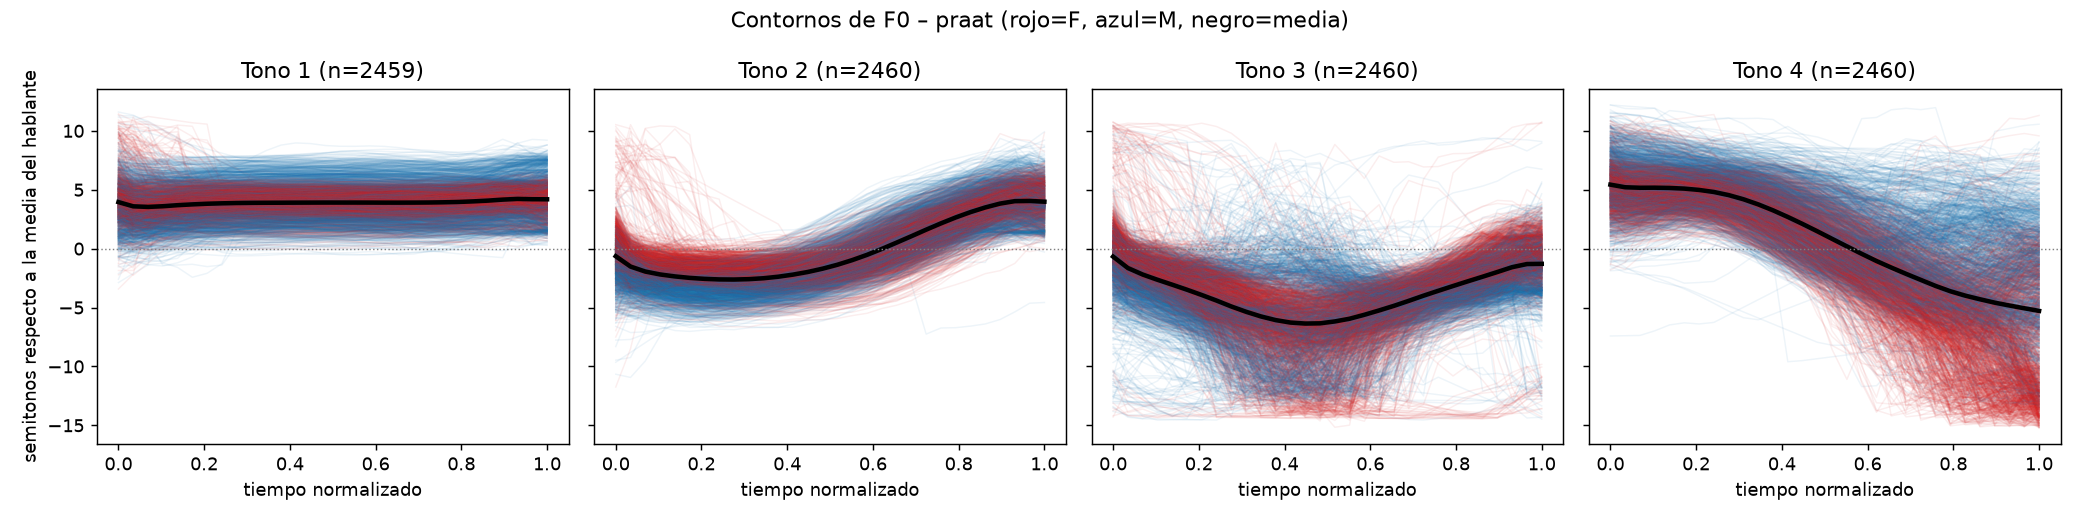

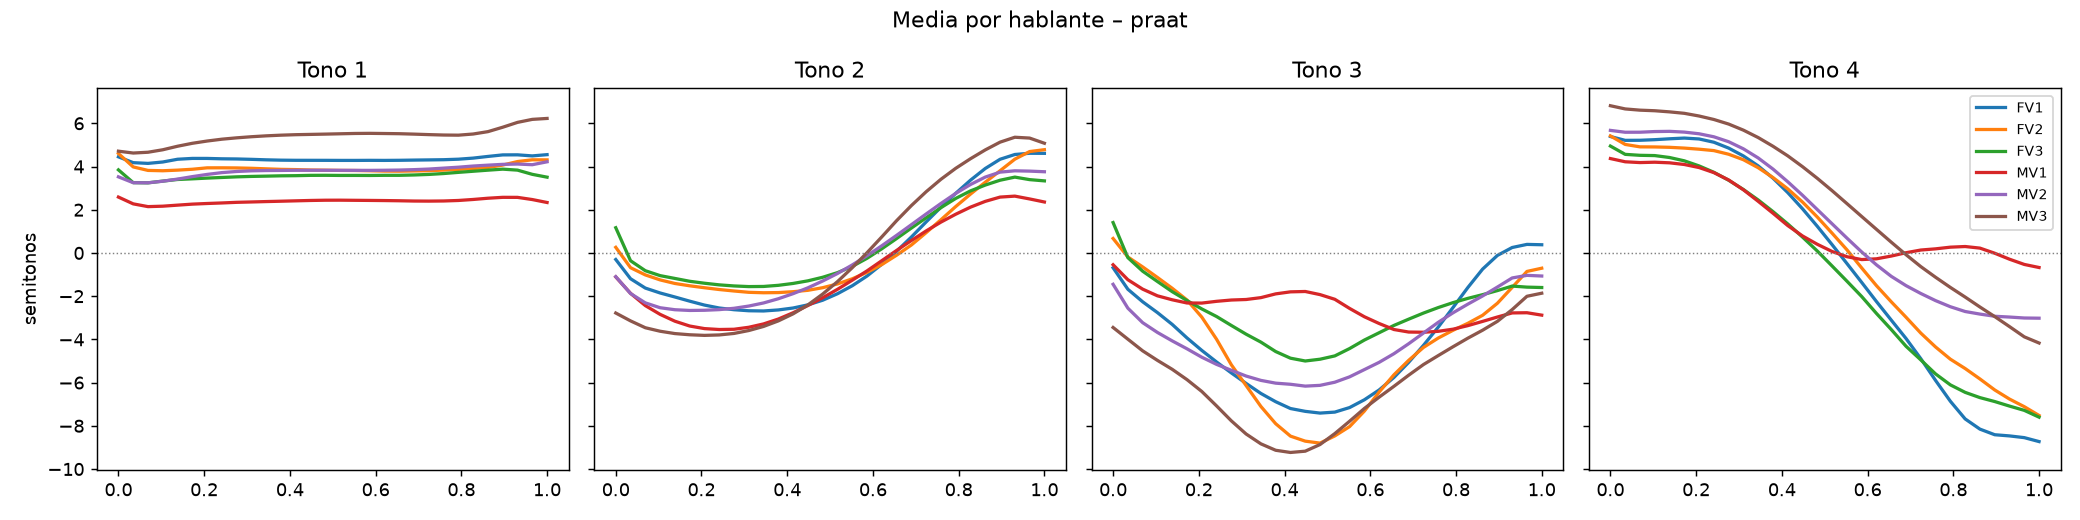

In [11]:
display(pd.crosstab(meta_30.speaker[jumps], meta_30.tone[jumps], rownames=["contornos con salto > 6 st"]))
show(OUT / "contornos" / "contornos_por_tono_praat.png")
show(OUT / "contornos" / "contornos_por_hablante_praat.png")

Queda un 4,4 % de T3 y un 3,5 % de T4 con algún salto de más de 6 st, concentrados en los T3 de FV2 y los T4 de FV1. La mayoría son saltos de 6–9 st que la corrección deja sin tocar a propósito, porque no se puede saber si son reales o un error de Praat que no es de octava (otro candidato a una quinta o una sexta). Los T3 con mediana muy baja (1,6 %) parecen descensos reales hasta el suelo del rango con voz *creaky*, pero no se han revisado uno por uno. Se aceptó este residuo: resolverlo exigiría otro estimador o heurísticas específicas por tono, y los clasificadores de las secciones siguientes ya llegan al 98–99 %.

En la figura por hablante se ve también lo que la normalización no resuelve: el valle de T3 va de unos −3 st (MV1) a −9 st (MV3), y el final de T4 de −0,5 st (MV1) a −8,5 st (FV1). Centrar en la media del hablante iguala el nivel, no la amplitud.

## 4. Baseline: features de F0 + LightGBM

`03_features_toneperfect.py` extrae el F0 corregido de todo el corpus y calcula por sílaba las mismas features que el baseline de AISHELL-3 (`tonos.features.contour_features`): el contorno remuestreado a 10 puntos, estadísticos (media, desviación, mínimo, máximo, rango, posición del mínimo y del máximo), pendiente, coeficientes de un polinomio de grado 2, diferencias entre el inicio, la mitad y el final, la fracción de frames sonoros y la duración.

`21_baseline_toneperfect.py` entrena LightGBM con los mismos hiperparámetros que el baseline de AISHELL-3, para que sean comparables, y evalúa dejando fuera un hablante por fold. Compara dos conjuntos: con y sin la duración.

In [12]:
baseline = load_json(OUT / "baseline_toneperfect" / "praat" / "metrics.json")
pd.DataFrame({
    name: {"accuracy": r["global"]["accuracy"], "macro-F1": r["global"]["macro_f1"],
           "media entre hablantes": r["accuracy_hablante_media_std"][0],
           "desv. entre hablantes": r["accuracy_hablante_media_std"][1],
           **{f"recall T{t}": r["global"]["recall_por_tono"][str(t)] for t in TONES},
           **{s: v["accuracy"] for s, v in r["por_hablante"].items()}}
    for name, r in baseline.items()
}).round(3)

,base,con_duracion
accuracy,0.983,0.976
macro-F1,0.983,0.976
media entre hablantes,0.983,0.976
desv. entre hablantes,0.014,0.035
recall T1,0.996,0.996
recall T2,0.983,0.986
recall T3,0.963,0.928
recall T4,0.989,0.995
FV1,0.987,0.989
FV2,0.990,0.993


**Quitar la duración mejora el modelo** (0,983 frente a 0,976) y, sobre todo, reduce la dispersión entre hablantes de 0,035 a 0,014. La causa está en MV1: el modelo aprende de los otros cinco que T3 es largo, y los T3 de MV1 duran 0,60 s, menos que el T4 de varios hablantes. La matriz de MV1 lo muestra:

In [13]:
for name in ["con_duracion", "base"]:
    oof = predictions(OUT / "baseline_toneperfect" / "praat" / f"oof_{name}.parquet")
    mv1 = oof[oof.speaker == "MV1"]
    print(f"MV1 · {name}")
    display(pd.crosstab(mv1.tone, mv1.pred, rownames=["real"], colnames=["predicho"]))

MV1 · con_duracion


predicho,1,2,3,4
real,,,,
1,406,3,0,1
2,0,407,3,0
3,1,11,257,141
4,7,0,0,403


MV1 · base


predicho,1,2,3,4
real,,,,
1,407,3,0,0
2,0,405,5,0
3,0,3,355,52
4,13,3,0,394


Con duración, 141 de los 410 T3 de MV1 (34 %) salen como T4; sin ella, 52. **Decisión: el conjunto por defecto (`base`) no usa la duración**, y `con_duracion` se conserva solo como comparativa. El argumento va más allá de Tone Perfect: los hispanohablantes que usarán la app no hablarán al ritmo de estos seis nativos, y un modelo que se apoya en la duración fallaría con ellos por una razón que no tiene que ver con el tono.

Los 52 T3 de MV1 que siguen fallando coinciden con lo visto en la sección 3: su T3 baja poco (unos −2 a −3,5 st) y casi no vuelve a subir, así que se parece a un T4 suave.

In [14]:
pd.read_csv(OUT / "baseline_toneperfect" / "praat" / "importancia_base.csv", index_col=0).squeeze().head(10).round(0)

slope     56063.0
min       35096.0
mean      21099.0
delta     10251.0
c4         8591.0
std        7957.0
c2         6960.0
max        5996.0
range      4584.0
voiced     4371.0
Name: 0, dtype: float64

## 5. Calibración de probabilidades (temperature scaling)

La app dará feedback según la probabilidad del tono objetivo, así que esas probabilidades deben significar lo que dicen: si el modelo dice 0,8, debería acertar 8 de cada 10 veces. *Temperature scaling* divide los logits por un único escalar T ajustado minimizando la NLL. No cambia la clase predicha (la accuracy es la misma) y, al tener un solo parámetro, apenas puede sobreajustar.

**Evaluación sin fuga de información.** Ajustar T con las mismas etiquetas con las que se evalúa daría una calibración optimista. Por eso `22_calibrar_toneperfect.py` sigue el mismo esquema que el entrenamiento: la T aplicada a cada hablante se ajusta con las probabilidades *out-of-fold* de los otros cinco. La T final, ajustada con los seis, es la que se guarda para la app.

In [15]:
calibration_runs = {
    "LightGBM base": OUT / "calibracion_toneperfect" / "praat" / "base" / "metrics.json",
    "LightGBM con_duracion": OUT / "calibracion_toneperfect" / "praat" / "con_duracion" / "metrics.json",
    "CNN": OUT / "calibracion_toneperfect" / "praat" / "cnn" / "metrics.json",
    "HuBERT + lineal": OUT / "calibracion_toneperfect" / "chinese-hubert-base" / "lineal" / "metrics.json",
}
rows = {}
for name, path in calibration_runs.items():
    r = load_json(path)
    rows[name] = {"T final": r["temperatura_final"],
                  **{f"{k} antes": r["sin_calibrar"][k] for k in ["ece", "nll", "brier"]},
                  **{f"{k} después": r["calibrado"][k] for k in ["ece", "nll", "brier"]}}
pd.DataFrame(rows).T.round(4)

,T final,ece antes,nll antes,brier antes,ece después,nll después,brier después
LightGBM base,1.649,0.011,0.073,0.029,0.002,0.059,0.028
LightGBM con_duracion,1.711,0.015,0.094,0.039,0.005,0.080,0.038
CNN,1.283,0.004,0.043,0.019,0.001,0.041,0.019
HuBERT + lineal,1.176,0.003,0.031,0.016,0.002,0.033,0.016


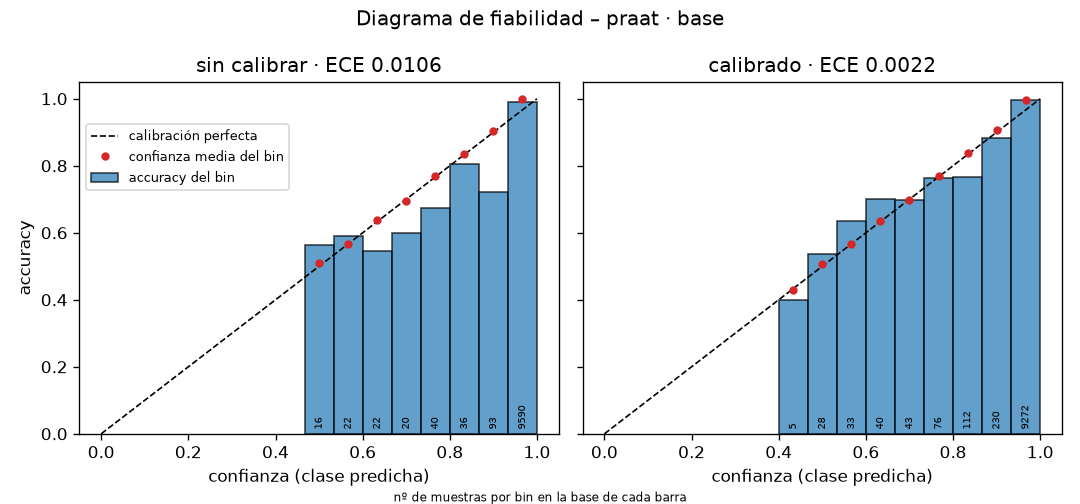

In [16]:
show(OUT / "calibracion_toneperfect" / "praat" / "base" / "fiabilidad.png")

LightGBM estaba **sobreconfiado** (T = 1,65 suaviza sus probabilidades) y la calibración baja su ECE de 0,011 a 0,002. La CNN sale bastante mejor calibrada de origen y la temperatura la mejora poco. Con HuBERT la calibración no compensa: baja el ECE pero sube la NLL, así que ese modelo es mejor sin calibrar.

Dos límites a tener presentes. Primero, el 95 % de las muestras cae en el último bin de confianza (≥ 0,93), así que la calibración en la zona de confianza media, la que importa para dar feedback a un aprendiz, se mide con pocas decenas de ejemplos por bin. Segundo, una única T no corrige diferencias entre hablantes: en LightGBM, MV1 sigue siendo el peor calibrado tras la temperatura (ECE de 0,032 a 0,021), y FV3 y MV3, que ya estaban bien, empeoran ligeramente. Con hispanohablantes habrá que recalibrar con sus grabaciones, porque el modelo fallará más y probablemente estará más sobreconfiado.

## 6. CNN 1D sobre el contorno de F0

Las features del baseline resumen el contorno en unos pocos números elegidos a mano. La CNN (`src/tonos/cnn.py`, `23_cnn_toneperfect.py`) recibe el contorno entero y aprende qué formas importan. Las decisiones de diseño:

- **Entrada: contorno de 64 puntos y su derivada.** El contorno se remuestrea a longitud fija, por lo que el modelo no ve la duración, igual que el conjunto `base` del baseline. La derivada se da explícita porque la pendiente es lo que más distingue los tonos.
- **Arquitectura:** tres bloques convolución + BatchNorm + ReLU + max-pooling y una capa lineal sobre el mapa **aplanado**. No se usa pooling global porque borraría *dónde* ocurre cada forma: T2 y T3 tienen ambos un valle, y lo que los separa es su posición en el tiempo.
- **Entrenamiento:** 40 épocas fijas con AdamW y OneCycle, **sin early stopping**. Con un hablante de test por fold, parar mirando su pérdida sería elegir el modelo con datos de test.

Los hiperparámetros son razonables pero no se optimizaron.

In [17]:
from tonos.cnn import ContourCNN

print(ContourCNN(n_points=64))
print("parámetros:", sum(p.numel() for p in ContourCNN(n_points=64).parameters()))

ContourCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(2, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): D

accuracy 0.988 · media ± desv. entre hablantes 0.988 ± 0.012
recall por tono: {'1': 0.9963, '2': 0.9846, '3': 0.9837, '4': 0.9862}
por hablante: {'FV1': 0.996, 'FV2': 0.991, 'FV3': 0.997, 'MV1': 0.963, 'MV2': 0.986, 'MV3': 0.994}


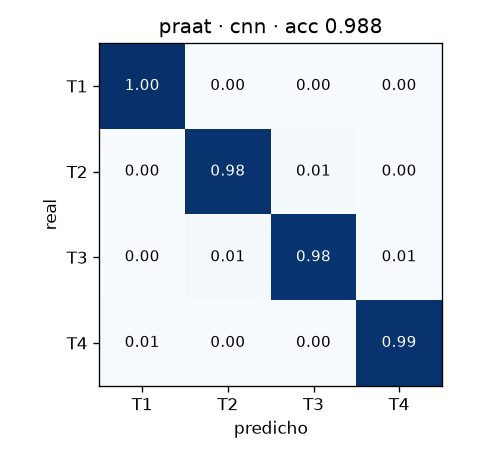

In [18]:
cnn = load_json(OUT / "cnn_toneperfect" / "praat" / "metrics.json")
print(f"accuracy {cnn['global']['accuracy']:.3f} · media ± desv. entre hablantes "
      f"{cnn['accuracy_hablante_media_std'][0]:.3f} ± {cnn['accuracy_hablante_media_std'][1]:.3f}")
print("recall por tono:", cnn["global"]["recall_por_tono"])
print("por hablante:", {s: round(v["accuracy"], 3) for s, v in cnn["por_hablante"].items()})
show(OUT / "cnn_toneperfect" / "praat" / "confusion_cnn.png", width=420)

La CNN llega a 0,988 (frente a 0,983 del baseline) y la mejora se concentra donde el baseline fallaba: el recall de T3 pasa de 0,963 a 0,984. Para descartar que fuera suerte de la inicialización se repitió con las semillas 1 y 2 (ejecución del 17 de noviembre, no guardada en `outputs/`): 0,987 en ambas, con MV1 en 0,960 y 0,963. MV1 sigue siendo el hablante más difícil, por la misma razón que en el baseline. El entrenamiento en GPU no es determinista del todo, así que una misma semilla puede variar ligeramente entre ejecuciones.

## 7. Embeddings congelados de HuBERT + clasificador lineal

El tercer enfoque no extrae el F0: usa la representación que un modelo de habla preentrenado aprende directamente del audio, sin ajustarlo (*congelado*), y entrena encima solo una regresión logística. Mide cuánta información de tono contienen esas representaciones.

- **Modelo:** `TencentGameMate/chinese-hubert-base`, preentrenado con habla en mandarín, como pedía el alcance ("idealmente en chino"). Está **fijado a un commit** (`fce0375`) para que el resultado sea reproducible aunque el repositorio del modelo cambie.
- **Representación:** media temporal de cada una de las 13 capas (`04_embeddings_toneperfect.py`), con el mismo preprocesado de audio que el F0. La media pierde el orden temporal; es la opción estándar para medir el contenido de los embeddings, pero no se comparó con alternativas.
- **Elección de capa sin fuga:** para cada hablante de test, la capa se elige con una validación interna (dejando fuera uno de los cinco de entrenamiento cada vez) y solo después se evalúa en el de test. La curva por capa de la figura se calcula directamente sobre el hablante de test y es **solo diagnóstico**: elegir su máximo sería optimista.
- **Regularización:** C = 1 con estandarización previa, sin ajustar.

capa elegida por hablante: {'FV1': 7, 'FV2': 8, 'FV3': 8, 'MV1': 8, 'MV2': 8, 'MV3': 8}
accuracy 0.990 · media ± desv. entre hablantes 0.990 ± 0.011
por hablante: {'FV1': 0.966, 'FV2': 0.999, 'FV3': 0.993, 'MV1': 0.988, 'MV2': 0.997, 'MV3': 0.997}


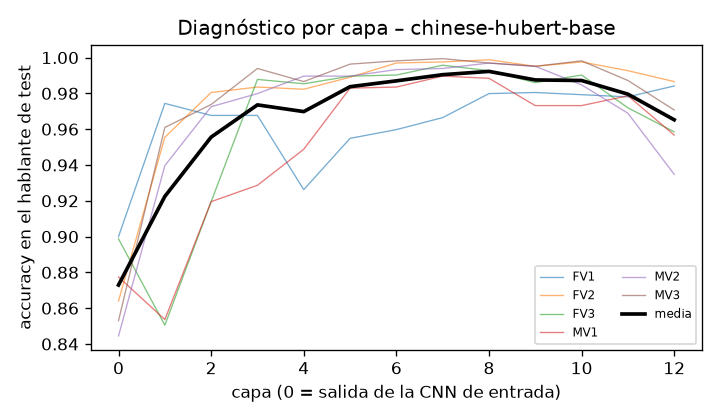

In [19]:
hubert = load_json(OUT / "lineal_toneperfect" / "chinese-hubert-base" / "metrics.json")
print("capa elegida por hablante:", hubert["capa_elegida_por_hablante"])
print(f"accuracy {hubert['global']['accuracy']:.3f} · media ± desv. entre hablantes "
      f"{hubert['accuracy_hablante_media_std'][0]:.3f} ± {hubert['accuracy_hablante_media_std'][1]:.3f}")
print("por hablante:", {s: round(v["accuracy"], 3) for s, v in hubert["por_hablante"].items()})
show(OUT / "lineal_toneperfect" / "chinese-hubert-base" / "accuracy_por_capa.png", width=600)

La validación interna elige la capa 8 (la 7 para FV1), y la curva de diagnóstico va en la misma línea: 0,87 en la capa 0, 0,99 en las 7–8 y 0,965 en la 12. La información útil para el tono está en las capas intermedias, no en la última.

HuBERT queda ligeramente por encima de la CNN (0,990 frente a 0,988), pero sobre todo **falla en otro sitio**: su punto débil es FV1, con 55 T3 clasificados como T2, mientras que la CNN acierta casi todo FV1. La comparación de errores lo confirma:

In [20]:
cnn_oof = predictions(OUT / "cnn_toneperfect" / "praat" / "oof_cnn.parquet")
hubert_oof = predictions(OUT / "lineal_toneperfect" / "chinese-hubert-base" / "oof_lineal.parquet")
assert (cnn_oof[["syllable", "speaker", "tone"]].values == hubert_oof[["syllable", "speaker", "tone"]].values).all()
cnn_wrong, hubert_wrong = cnn_oof.pred != cnn_oof.tone, hubert_oof.pred != hubert_oof.tone
print(f"errores CNN {cnn_wrong.sum()} · errores HuBERT {hubert_wrong.sum()} · comunes {(cnn_wrong & hubert_wrong).sum()}")
fv1 = hubert_oof[hubert_oof.speaker == "FV1"]
display(pd.crosstab(fv1.tone, fv1.pred, rownames=["real FV1"], colnames=["predicho HuBERT"]))

errores CNN 121 · errores HuBERT 98 · comunes 2


predicho HuBERT,1,2,3,4
real FV1,,,,
1,410,0,0,0
2,0,410,0,0
3,0,55,355,0
4,0,0,0,410


De los 121 errores de la CNN y los 98 de HuBERT solo 2 son comunes: los dos enfoques ven cosas distintas (uno el F0 explícito, otro el espectro completo). No se ha explorado combinarlos.

## 8. Comparativa

Todos los modelos con el mismo esquema (un hablante fuera por fold) y ninguno usa la duración salvo `con_duracion`.

In [21]:
models = {
    "LightGBM con_duracion": baseline["con_duracion"],
    "LightGBM base": baseline["base"],
    "CNN contorno": cnn,
    "HuBERT + lineal": hubert,
}
calibration_key = {"LightGBM con_duracion": "LightGBM con_duracion", "LightGBM base": "LightGBM base",
                   "CNN contorno": "CNN", "HuBERT + lineal": "HuBERT + lineal"}
summary = {}
for name, r in models.items():
    cal = load_json(calibration_runs[calibration_key[name]])
    worst = min(r["por_hablante"].items(), key=lambda kv: kv[1]["accuracy"])
    summary[name] = {"accuracy": r["global"]["accuracy"],
                     "media entre hablantes": r["accuracy_hablante_media_std"][0],
                     "desv. entre hablantes": r["accuracy_hablante_media_std"][1],
                     "recall T3": r["global"]["recall_por_tono"]["3"],
                     "peor hablante": f"{worst[0]} ({worst[1]['accuracy']:.3f})",
                     "ECE sin calibrar": cal["sin_calibrar"]["ece"],
                     "ECE calibrado": cal["calibrado"]["ece"]}
pd.DataFrame(summary).T

,accuracy,media entre hablantes,desv. entre hablantes,recall T3,peor hablante,ECE sin calibrar,ECE calibrado
LightGBM con_duracion,0.976,0.976,0.035,0.928,MV1 (0.898),0.015,0.005
LightGBM base,0.983,0.983,0.014,0.963,MV1 (0.952),0.011,0.002
CNN contorno,0.988,0.988,0.012,0.984,MV1 (0.963),0.004,0.001
HuBERT + lineal,0.99,0.99,0.011,0.969,FV1 (0.966),0.003,0.002


**Decisión para el MVP: la CNN calibrada.** HuBERT queda 0,2 puntos por encima, una diferencia del orden de la variación entre semillas de la CNN, mientras que la inferencia de la CNN solo necesita el F0 (Praat) y un modelo de 113 KB, frente a los ~380 MB de HuBERT. La interpretabilidad también cuenta en una app de aprendizaje: el contorno que clasifica la CNN es el mismo que se le muestra al usuario frente al contorno objetivo.

Estas cifras rozan el techo y no deben leerse como la precisión de la app. Son seis nativos leyendo sílabas aisladas en condiciones de laboratorio. La medida que importa para el TFM es la caída de rendimiento con hispanohablantes, pendiente de sus grabaciones.

## 9. Del modelo al MVP: backend de inferencia

`25_entrenar_cnn_final.py` entrena la CNN con los seis hablantes y la guarda en un único artefacto (`models/cnn_toneperfect_praat.pt`) con los pesos, el método de F0, la temperatura de la calibración *out-of-fold* (T = 1,28) y el contorno objetivo de cada tono (la media del corpus). La temperatura es una aproximación: el modelo final se entrena con más datos que cada fold.

**El problema de la normalización en producción.** El modelo espera el F0 en semitonos respecto a la media del hablante, y con una sola sílaba de un usuario nuevo esa media no existe. La solución es un paso de calibración de voz: el usuario graba una sílaba en los cuatro tonos (p. ej. mā má mǎ mà), y de ahí se obtiene su perfil (referencia y rango de F0) con el mismo procedimiento de dos pasadas y corrección de octava que en el entrenamiento. Los cuatro tonos son necesarios para que la media no se sesgue, igual que en Tone Perfect cada hablante tiene los cuatro tonos por igual.

La lógica está en `src/tonos/inference.py`, sin dependencias web; `src/tonos/api.py` es una capa FastAPI fina con `POST /api/calibrate` y `POST /api/analyze`. El backend no guarda estado: el cliente conserva el perfil y lo envía en cada análisis. Aquí se usa la misma lógica en el propio proceso, sin servidor:

perfil MV1 con 4 grabaciones: referencia 140.9 Hz, rango 60–246 Hz
referencia con las 1.640 grabaciones: 146.4 Hz (diferencia -0.67 st)


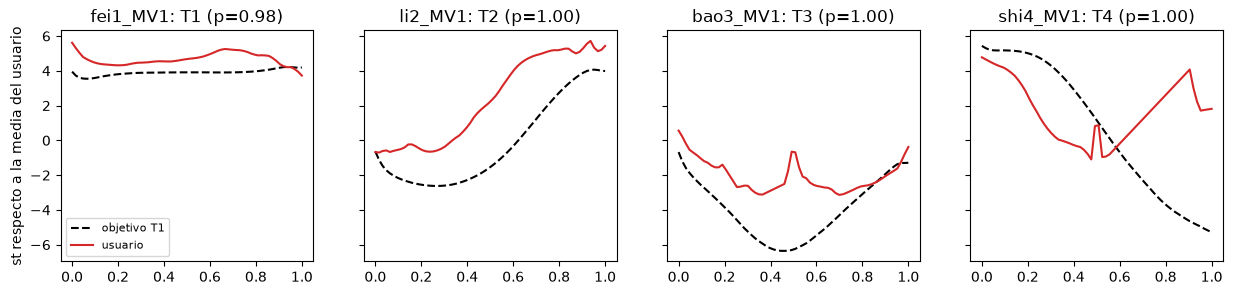

In [22]:
from tonos.f0 import load
from tonos.inference import ToneClassifier

classifier = ToneClassifier(ROOT / "models" / "cnn_toneperfect_praat.pt")
profile = classifier.build_profile([load(audio_path(f"ma{t}_MV1")) for t in TONES])
corpus_reference = stored["refs"].item()["MV1"]
print(f"perfil MV1 con 4 grabaciones: referencia {profile.reference_hz:.1f} Hz, rango {profile.fmin:.0f}–{profile.fmax:.0f} Hz")
print(f"referencia con las 1.640 grabaciones: {corpus_reference:.1f} Hz "
      f"(diferencia {12 * np.log2(profile.reference_hz / corpus_reference):+.2f} st)")

examples = ["fei1_MV1", "li2_MV1", "bao3_MV1", "shi4_MV1"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, name in zip(axes, examples):
    target = int(name.split("_")[0][-1])
    result = classifier.analyze(load(audio_path(name)), profile, target_tone=target)
    x = np.linspace(0, 1, len(result.contour_st))
    ax.plot(x, result.target_contour_st, "k--", label=f"objetivo T{target}")
    ax.plot(x, result.contour_st, color="tab:red", label="usuario")
    ax.set_title(f"{name}: T{result.tone} (p={result.probabilities[result.tone]:.2f})")
axes[0].set_ylabel("st respecto a la media del usuario")
axes[0].legend(fontsize=8)
plt.show()

Estas sílabas de MV1 están en el entrenamiento del modelo final, así que la demo solo prueba que el circuito funciona, no que generalice. El contorno de `shi4_MV1` muestra además un artefacto que el usuario vería: tras un hueco sordo, el final del T4 aparece unos 5 st por encima y la interpolación lo une con una rampa ascendente. No es un error de octava, así que la corrección no lo toca, y el modelo acierta igualmente.

**El perfil de 4 grabaciones tiene un coste pequeño.** Con la referencia calculada solo con *ma* en los cuatro tonos, la media de cada hablante se desvía de la de su corpus completo entre +0,2 y −2,0 st (MV3). `28_evaluar_calibracion.py` mide el efecto con una CNN entrenada sin cada hablante y todas sus sílabas (salvo las de calibración): 0,984 de accuracy con el perfil de *ma*, frente a 0,988 con la referencia del corpus sobre las mismas sílabas. El coste depende del hablante: MV3 pierde 1,8 puntos y MV1 gana 1,1. Una primera estimación sobre 100 sílabas por hablante (sección 10) había dado 0,970, una cifra que resultó ser ruido de muestreo.

**Calibrar con más sílabas empeora.** La hipótesis era que combinar vocales distintas compensaría la altura propia de cada vocal. El resultado es el contrario:

In [23]:
calibration_sets = load_json(OUT / "calibracion_perfil" / "metrics.json")
pd.DataFrame({name: {k: v for k, v in s.items() if not isinstance(v, dict)} for name, s in calibration_sets.items()}).T

,grabaciones,desviacion_abs_media_st,desviacion_abs_max_st,accuracy_media,accuracy_minima
ma,4.0,0.766,1.976,0.984,0.974
ma+yi,8.0,0.765,1.680,0.977,0.927
ma+yi+wu,12.0,0.673,1.338,0.972,0.885
ma+yi+wu+li,16.0,0.673,1.338,0.971,0.885


Las vocales altas de *yi* y *wu* suben la referencia, y en MV1 la llevan a +1,34 st, con lo que su accuracy cae al 0,886. **Decisión: calibrar solo con *ma*.** La desviación que queda (hasta 2 st en MV3) sería mejor tratarla en el modelo, haciéndolo robusto a errores de referencia, que pidiendo más grabaciones al usuario.

**El frontend** (React + Vite, en `frontend/`) graba con el formato nativo del navegador y lo convierte a WAV antes de enviarlo, porque la API no decodifica webm/opus. El backend sirve el frontend compilado en `/` y la API en `/api`, desde el mismo origen, así que no hace falta CORS. La práctica ofrece las 408 sílabas de Tone Perfect (`05_exportar_silabas_toneperfect.py`), pero solo las 1.243 combinaciones sílaba-tono que son palabras reales, con su pinyin y sus caracteres del propio corpus. Las 397 restantes son huecos léxicos (sílabas grabadas en un tono en el que no existen como palabra, como *bán*) y practicarlas aporta poco a un aprendiz.

## 10. Voz corregida con WORLD

Tras grabar, el usuario puede escuchar **su propia voz con la entonación correcta** (`src/tonos/resynthesis.py`, endpoint `POST /api/resynthesize`). WORLD descompone la grabación en F0, envolvente espectral (el timbre y la vocal) y aperiodicidad; se sustituye solo el F0 por el contorno objetivo y se vuelve a sintetizar. Decisiones:

- **El contorno objetivo se expresa en semitonos respecto a la media del usuario**, así que la corrección conserva su registro: no suena como el hablante nativo, sino como él mismo diciendo el tono correcto.
- **Solo se cambian los frames con voz.** Forzar F0 donde WORLD solo ve ruido produce un zumbido.
- **Harvest se acota al rango del perfil**, por la misma razón que el análisis: un error de octava en la resíntesis se oiría como un salto.
- **Se resintetiza a la frecuencia original del audio** (hasta 48 kHz) para no perder calidad; tarda unos 0,1 s por sílaba.

### 10.1 Evaluación objetiva

`26_evaluar_voz_corregida.py` resintetiza 100 sílabas de cada hablante hacia los cuatro tonos (2.400 resíntesis). Para que no haya fuga, con cada hablante se entrena una CNN con los otros cinco, la plantilla objetivo sale de esos cinco y el perfil se calcula como en la app.

resíntesis: 2400 · sin voz detectable: 0
CNN sobre las originales: 0.970
CNN reconoce el tono objetivo (tono cambiado): 0.998 · control mismo tono: 0.992
error de F0 (mediana, st) según el desplazamiento pedido: {'(0.0, 3.0]': 0.187, '(3.0, 6.0]': 0.187, '(6.0, 9.0]': 0.262, '(9.0, inf]': 0.429}


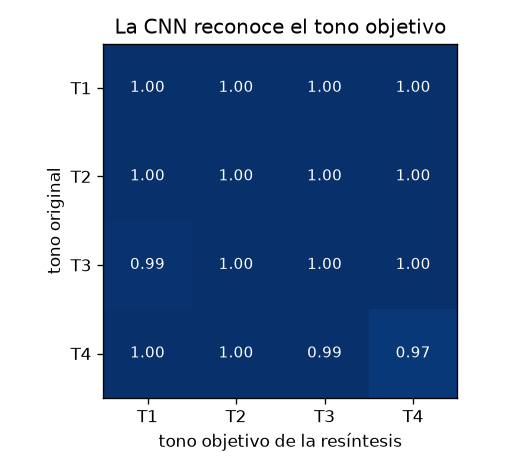

In [24]:
voice = load_json(OUT / "voz_corregida" / "metrics.json")
print(f"resíntesis: {voice['n_resintesis']} · sin voz detectable: {voice['fallos_sin_voz']}")
print(f"CNN sobre las originales: {voice['accuracy_originales']:.3f}")
print(f"CNN reconoce el tono objetivo (tono cambiado): {voice['accuracy_tono_cambiado']:.3f} · control mismo tono: {voice['accuracy_control_mismo_tono']:.3f}")
print("error de F0 (mediana, st) según el desplazamiento pedido:", voice["error_f0_st_mediana_por_desplazamiento"])
show(OUT / "voz_corregida" / "accuracy_origen_objetivo.png", width=420)

La CNN reconoce el tono objetivo en el 99,8 % de las resíntesis y el F0 medido después se queda a unos 0,2 st del objetivo, con más error cuanto mayor es el desplazamiento (0,43 st por encima de 9 st). **Esto comprueba que el F0 cambia como se pide, pero es una medida circular**: si el F0 resultante es la plantilla, un clasificador de F0 la reconoce casi por construcción. Lo que no mide es cómo suena (naturalidad, artefactos), que es lo que importa a un aprendiz. En `outputs/voz_corregida/ejemplos/` hay una sílaba de cada hablante convertida a los cuatro tonos para escucharla; una evaluación perceptiva con oyentes queda pendiente.

### 10.2 Plantilla fija frente a un contorno objetivo personalizado

El alcance planteaba predecir el contorno objetivo con un modelo ligero a partir del rango y la duración del hablante, en vez de usar una plantilla fija. `27_contorno_objetivo_personalizado.py` lo compara dejando fuera un hablante cada vez: para cada sílaba del hablante de test se predice su contorno real con la plantilla (media de los otros cinco), con una regresión Ridge por tono sobre la duración, y con otra sobre la duración y el rango de F0 de su calibración.

In [25]:
personal = load_json(OUT / "contorno_objetivo" / "metrics.json")
print("rango de calibración (st):", {s: round(v, 1) for s, v in personal["rango_calibracion_st"].items()})
display(pd.DataFrame(personal["rmse_por_hablante_st"]).T)
print("RMSE medio (st):", personal["rmse_medio_st"])

rango de calibración (st): {'FV1': 11.5, 'FV2': 8.1, 'FV3': 6.8, 'MV1': 6.9, 'MV2': 9.5, 'MV3': 10.1}


,plantilla,duracion,duracion_rango
FV1,1.903,1.826,2.299
FV2,2.130,2.121,2.189
FV3,1.755,1.790,1.745
MV1,2.716,2.932,2.644
MV2,1.679,1.724,1.752
MV3,2.617,2.800,2.433


RMSE medio (st): {'plantilla': 2.1335, 'duracion': 2.1988, 'duracion_rango': 2.177}


**La plantilla gana** (2,13 st de RMSE medio frente a 2,18 con duración y rango). El modelo con rango mejora en tres hablantes (FV3, MV1, MV3) y empeora mucho en FV1, el de mayor rango: con solo cinco hablantes de entrenamiento, el efecto del rango se estima con cinco valores distintos y no generaliza. La duración solo ayuda en T4, donde las sílabas más largas caen más. **Decisión: la app usa la plantilla.** Con más hablantes (AISHELL-3 tiene 218) el modelo personalizado podría compensar; queda como trabajo futuro.

## 11. Decisiones y límites

| Decisión | Motivo | Alternativa descartada |
|---|---|---|
| Evaluar dejando fuera un hablante (6 folds) | Medir el rendimiento con voces no vistas | Splits aleatorios: el mismo hablante en train y test infla la accuracy |
| Praat como estimador de F0 | 0 % de fallos; pYIN perdía el 10 % de T4 y recortaba su caída | pYIN; CREPE no se comparó en Tone Perfect |
| Rango por hablante + corrección por continuidad con bordes robustos | Elimina los saltos de octava sin tocar las caídas reales de T4 ni los saltos reales de 6–9 st | `clean_f0` (altera la mitad de los T4); tramo más largo como referencia (movía T3 enteros); borde de un frame y umbral de 6 st (desplazaba tramos correctos) |
| Sin duración en las features | Atajo que no transfiere: 34 % de los T3 de MV1 como T4 | Usarla: −0,007 de accuracy global y −0,054 en MV1 |
| Temperatura ajustada con los otros cinco hablantes | Calibración sin fuga de información | Ajustar T con las mismas etiquetas de evaluación |
| CNN sin early stopping, épocas fijas | No elegir el modelo mirando al hablante de test | Validar sobre el fold de test |
| Capa de HuBERT por validación interna | No elegir la capa mirando al hablante de test | Quedarse con el máximo de la curva por capa |
| CNN calibrada para el MVP | A 0,2 puntos de HuBERT (del orden de la variación entre semillas), 113 KB, interpretable | HuBERT (~380 MB, inferencia más pesada) |
| Perfil de voz con los 4 tonos de una sílaba | El modelo necesita la media del hablante | Normalizar por la propia sílaba (destruye el nivel, que distingue T1) |
| Calibrar solo con *ma* | Más sílabas (*yi*, *wu*, *li*) sesgan la referencia hacia arriba: 0,984 → 0,971 de accuracy | Calibrar con 8–16 grabaciones |
| Solo palabras reales en la práctica | Practicar huecos léxicos aporta poco | Ofrecer las 1.640 combinaciones |
| Voz corregida con WORLD cambiando solo el F0 de los frames con voz | Conserva timbre y registro del usuario; sin zumbidos en tramos sordos | Forzar voz en todo el tramo |
| Plantilla fija como contorno objetivo | Gana al modelo personalizado (2,13 frente a 2,18 st) con 6 hablantes | Ridge sobre duración y rango |

Los límites, por orden de importancia. **Todo está medido con 6 nativos**: la caída con hispanohablantes es la medida central del TFM y está pendiente. **El residuo de F0** (4,4 % de T3 y 3,5 % de T4 con saltos de más de 6 st, sobre todo en FV2 y FV1) no es corregible con octavas. **Los hiperparámetros** de la CNN, de LightGBM y la C de la regresión logística no se ajustaron. **La calibración** en la zona de confianza media se apoya en pocos ejemplos, y una sola temperatura no corrige diferencias entre hablantes. **El perfil de 4 grabaciones** desvía la referencia hasta 2 st y cuesta 0,4 puntos de accuracy de media (1,8 en MV3); calibrar con más sílabas lo empeora. **La voz corregida** solo tiene evaluación objetiva y circular; falta la perceptiva.

## Continúa en el notebook 02

Las cifras de este notebook son de laboratorio. [02_escalera_dominio.ipynb](02_escalera_dominio.ipynb) mide qué queda de ellas en habla continua (AISHELL-3), compara contexto y HuBERT con una línea base léxica sin audio y comprueba con dos contrafactuales qué modelo oye de verdad el tono.